In [1]:
import lenet
import matplotlib.pyplot as plt
import networkx as nx
import onnx
import onnxruntime
import os
import time

In [2]:
model = onnx.load(lenet.onnx_filename)
model

ModelProto(ir_version=10, opset_import={'': 20}, producer_name='pytorch', producer_version='2.13.0+cpu', graph=GraphProto('main_graph', input=<1 inputs>, output=<1 outputs>, initializer=<11 initializers>, node=<12 nodes>, value_info=<22 value_info>))

# Save ONNX model with external data

It is possible to store tensor data of a model (weights, biases) separately from the ONNX model.
Inplementing a custom operators it is possible to load tensors on fly and thus 

In [3]:
try:
    os.remove("lenet_external.onnx.data")
except FileNotFoundError:
    pass


onnx.save_model(
    model,
    "lenet_external.onnx",
    save_as_external_data=True,
    all_tensors_to_one_file=True,
    location="lenet_external.onnx.data",
    size_threshold=0
)


# Draw a model network

In [4]:
def print_model(m):
    for node in m.graph.node:
        print("------------------------------------")
        print(node.name, node.input, node.output, [f'{a.name}={a.s if "s" in a else ""}' for a in node.attribute])

In [5]:
def draw_model(m):
    G = nx.DiGraph()
    producers = {}

    # Use distinct IDs so operator names cannot collide with tensor names.
    for index, node in enumerate(m.graph.node):
        node_id = ("operator", index)
        G.add_node(node_id, label=f"{node.name or f'operator_{index}'}\n({node.op_type})", kind="operator")
        for tensor_name in node.output:
            if tensor_name:
                producers[tensor_name] = node_id

    initializers = {tensor.name for tensor in m.graph.initializer}

    def connect(source, target, tensor_name):
        # A pair of operators can exchange more than one tensor.
        if G.has_edge(source, target):
            G.edges[source, target]["label"] += "\n" + tensor_name
        else:
            G.add_edge(source, target, label=tensor_name)

    for index, node in enumerate(m.graph.node):
        target = ("operator", index)
        for tensor_name in node.input:
            if not tensor_name:  # An omitted optional input has no edge.
                continue
            source = producers.get(tensor_name)
            if source is None:
                source = ("tensor", tensor_name)
                kind = "initializer" if tensor_name in initializers else "input"
                G.add_node(source, label=tensor_name, kind=kind)
            connect(source, target, tensor_name)

    for tensor in m.graph.output:
        output_id = ("output", tensor.name)
        G.add_node(output_id, label=tensor.name, kind="output")
        source = producers.get(tensor.name, ("tensor", tensor.name))
        if source not in G:
            G.add_node(source, label=tensor.name, kind="input")
        connect(source, output_id, tensor.name)

    for layer, nodes in enumerate(nx.topological_generations(G)):
        for node_id in nodes:
            G.nodes[node_id]["layer"] = layer

    pos = nx.multipartite_layout(G, subset_key="layer", align="horizontal")
    pos = {node_id: (x, -y) for node_id, (x, y) in pos.items()}
    colors = {"operator": "lightblue", "initializer": "lightgray", "input": "lightgreen", "output": "peachpuff"}

    fig, ax = plt.subplots(figsize=(24, 18))
    nx.draw_networkx(
        G, pos=pos, ax=ax,
        labels=nx.get_node_attributes(G, "label"),
        node_color=[colors[G.nodes[node_id]["kind"]] for node_id in G],
        node_shape="s", node_size=2600, font_size=8,
        arrows=True, arrowsize=18,
    )
    nx.draw_networkx_edge_labels(
        G, pos=pos, ax=ax,
        edge_labels=nx.get_edge_attributes(G, "label"),
        font_size=7, rotate=False,
    )
    ax.set_title("ONNX operators and tensor dependencies")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


In [6]:
print_model(model)

------------------------------------
node_conv2d ['images', 'lenet_stack.0.weight', 'lenet_stack.0.bias'] ['conv2d'] ['group=', 'pads=', "auto_pad=b'NOTSET'", 'strides=', 'dilations=', 'kernel_shape=']
------------------------------------
node_relu ['conv2d'] ['relu'] []
------------------------------------
node_avg_pool2d ['relu'] ['avg_pool2d'] ['count_include_pad=', 'ceil_mode=', 'pads=', "auto_pad=b'NOTSET'", 'strides=', 'kernel_shape=']
------------------------------------
node_conv2d_1 ['avg_pool2d', 'lenet_stack.3.weight', 'lenet_stack.3.bias'] ['conv2d_1'] ['group=', 'pads=', "auto_pad=b'NOTSET'", 'strides=', 'dilations=', 'kernel_shape=']
------------------------------------
node_relu_1 ['conv2d_1'] ['relu_1'] []
------------------------------------
node_avg_pool2d_1 ['relu_1'] ['avg_pool2d_1'] ['count_include_pad=', 'ceil_mode=', 'pads=', "auto_pad=b'NOTSET'", 'strides=', 'kernel_shape=']
------------------------------------
node_view ['avg_pool2d_1', 'val_3'] ['view'] ['allo

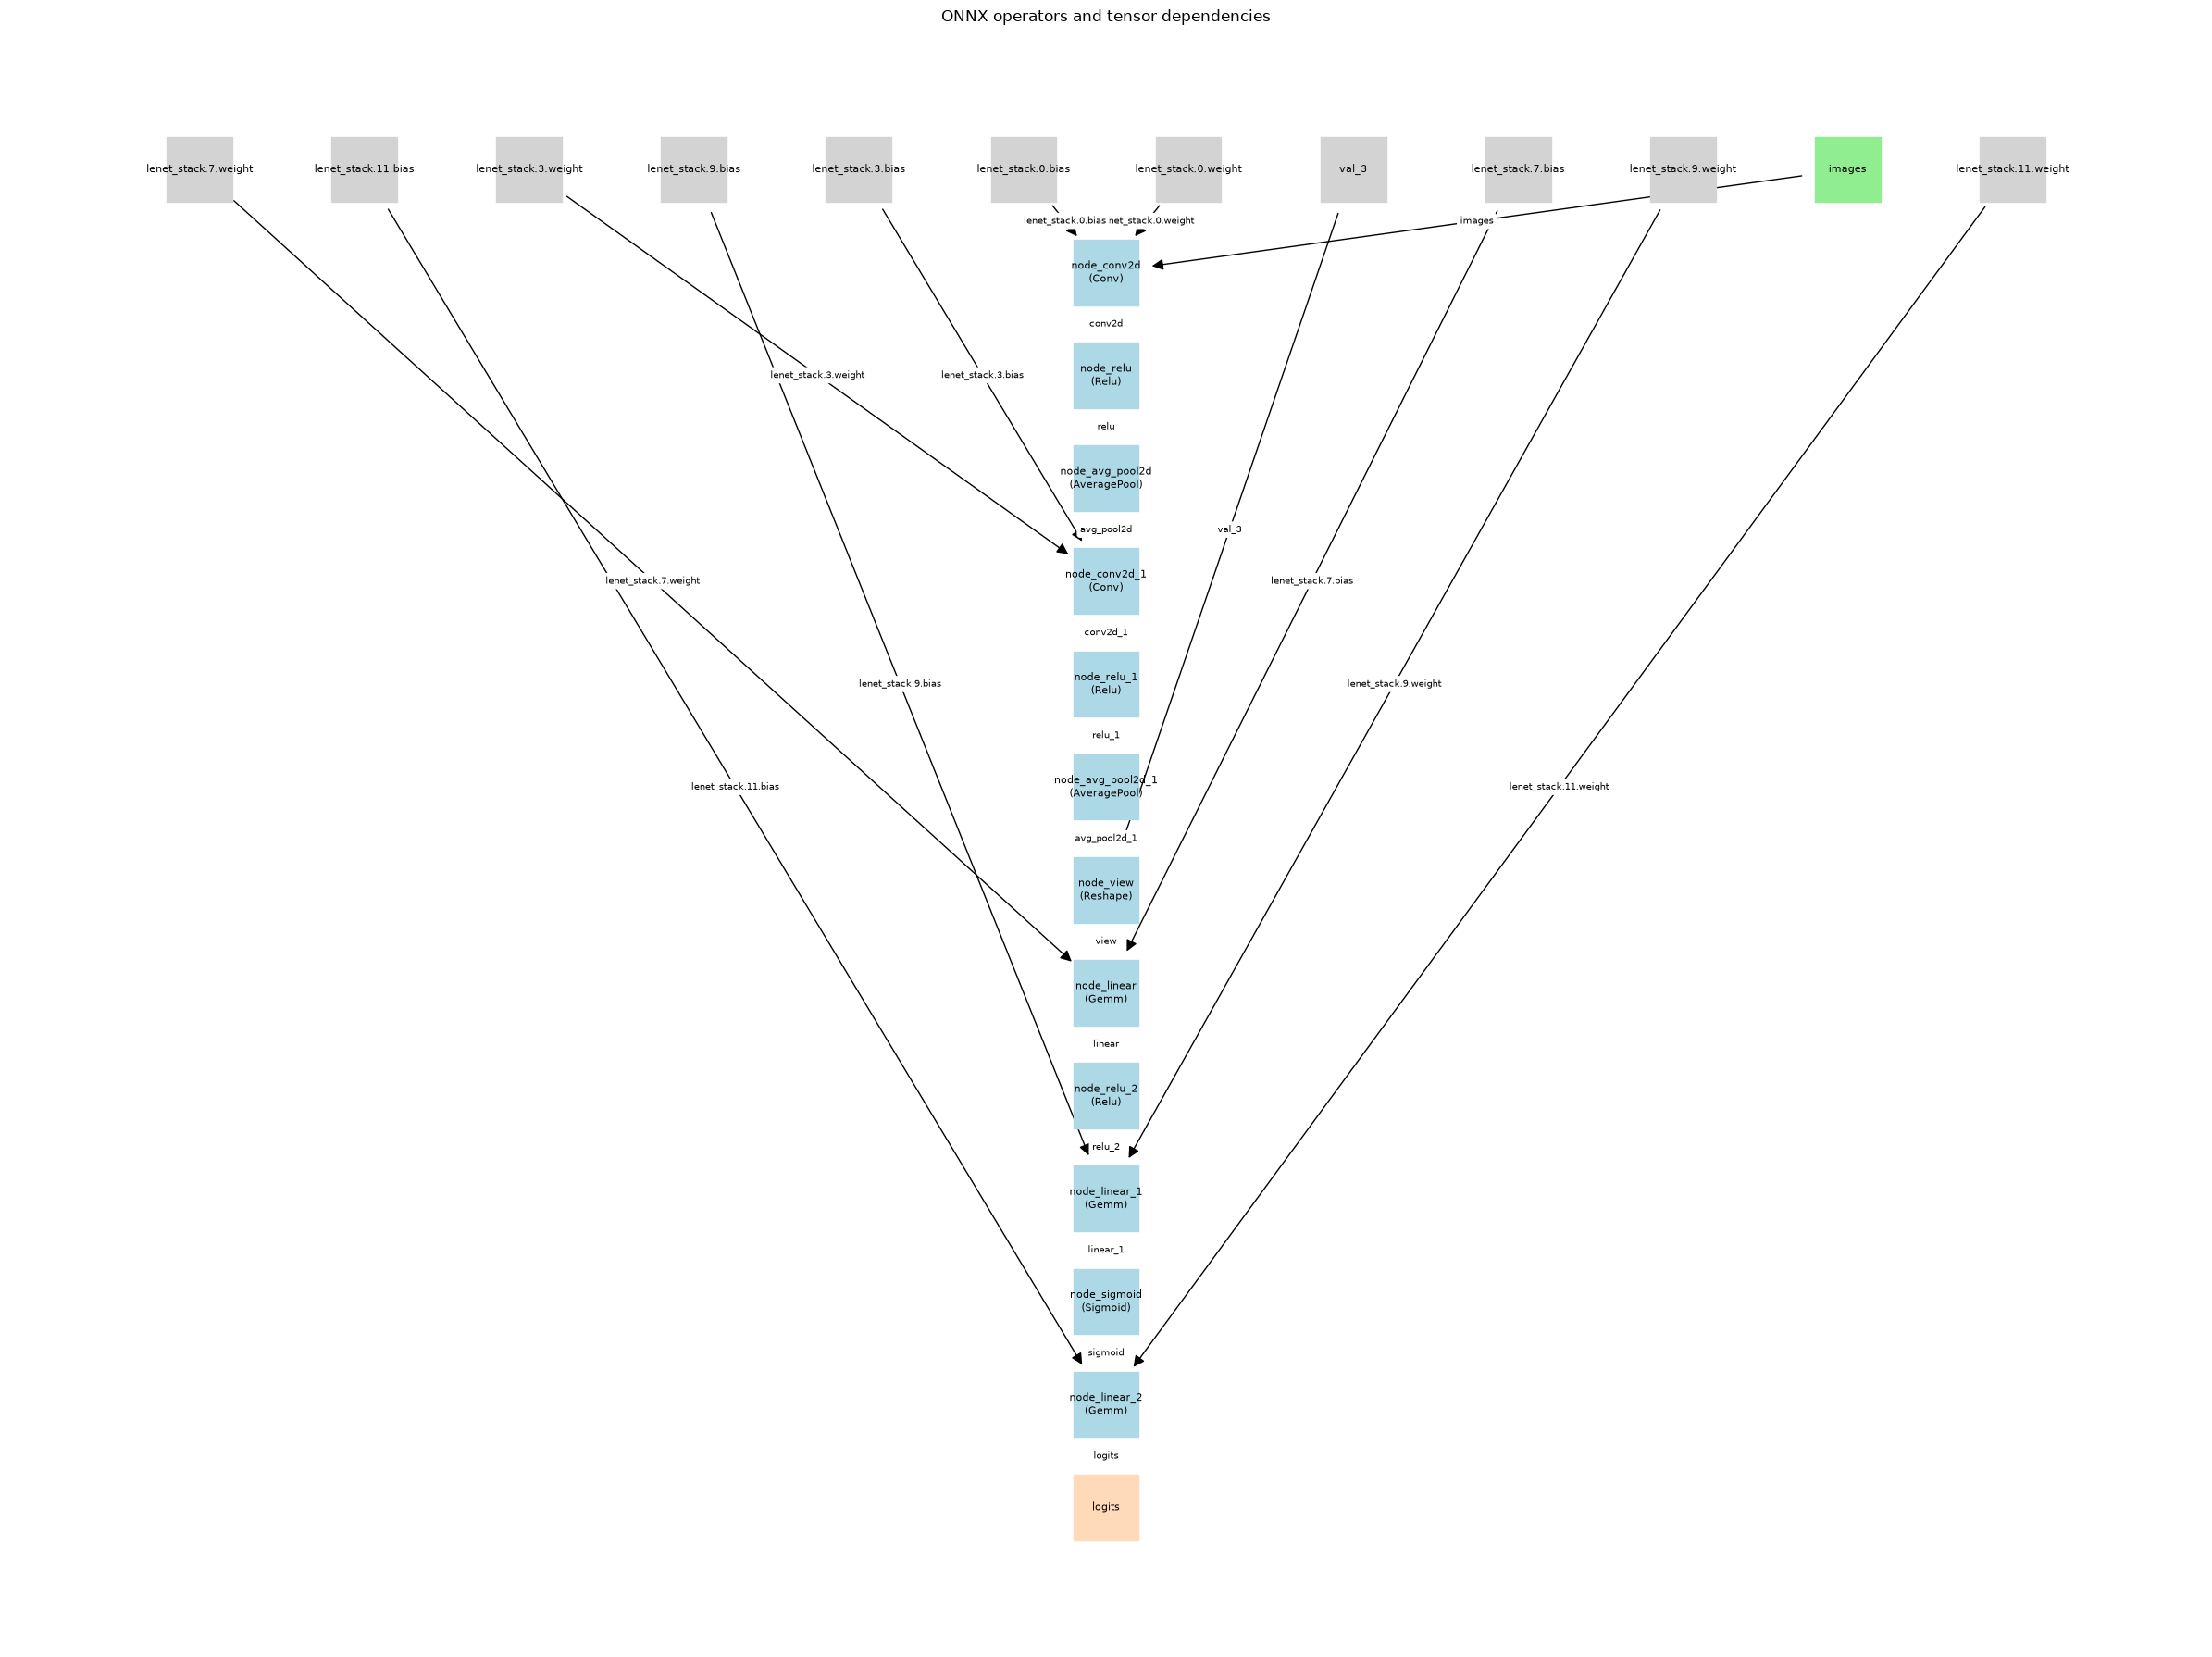

In [7]:
draw_model(model)

# ONNX Optimizations

In [8]:

sess_options = onnxruntime.SessionOptions()
sess_options.enable_profiling = True
sess_options.graph_optimization_level = onnxruntime.GraphOptimizationLevel.ORT_ENABLE_EXTENDED
sess_options.optimized_model_filepath = lenet.onnx_filename + ".optimized"

X = lenet.load_tensor(lenet.sample_filename)
y = lenet.load_tensor(lenet.labels_filename, "<i8")

onnxruntime_session = onnxruntime.InferenceSession(lenet.onnx_filename, sess_options)
pred_onnx = onnxruntime_session.run(None, {"images": X[0].reshape(1, *X[0].shape)})[0].reshape(-1)
prof_file = onnxruntime_session.end_profiling()

optimized_model = onnx.load(sess_options.optimized_model_filepath)

Tensor shape = (64, 1, 28, 28)
Tensor shape = (64,)


In [9]:
print_model(optimized_model)

------------------------------------
node_conv2d ['images', 'lenet_stack.0.weight', 'lenet_stack.0.bias'] ['relu'] ['strides=', "activation=b'Relu'", 'dilations=', "auto_pad=b'NOTSET'", 'pads=', 'kernel_shape=', 'group=']
------------------------------------
node_avg_pool2d ['relu'] ['avg_pool2d'] ['strides=', "auto_pad=b'NOTSET'", 'pads=', 'kernel_shape=', 'ceil_mode=', 'count_include_pad=']
------------------------------------
node_conv2d_1 ['avg_pool2d', 'lenet_stack.3.weight', 'lenet_stack.3.bias'] ['relu_1'] ['strides=', "activation=b'Relu'", 'dilations=', "auto_pad=b'NOTSET'", 'pads=', 'kernel_shape=', 'group=']
------------------------------------
node_avg_pool2d_1 ['relu_1'] ['avg_pool2d_1'] ['strides=', "auto_pad=b'NOTSET'", 'pads=', 'kernel_shape=', 'ceil_mode=', 'count_include_pad=']
------------------------------------
node_view ['avg_pool2d_1', 'val_3'] ['view'] ['allowzero=']
------------------------------------
fused node_linear ['view', 'lenet_stack.7.weight', 'lenet_st

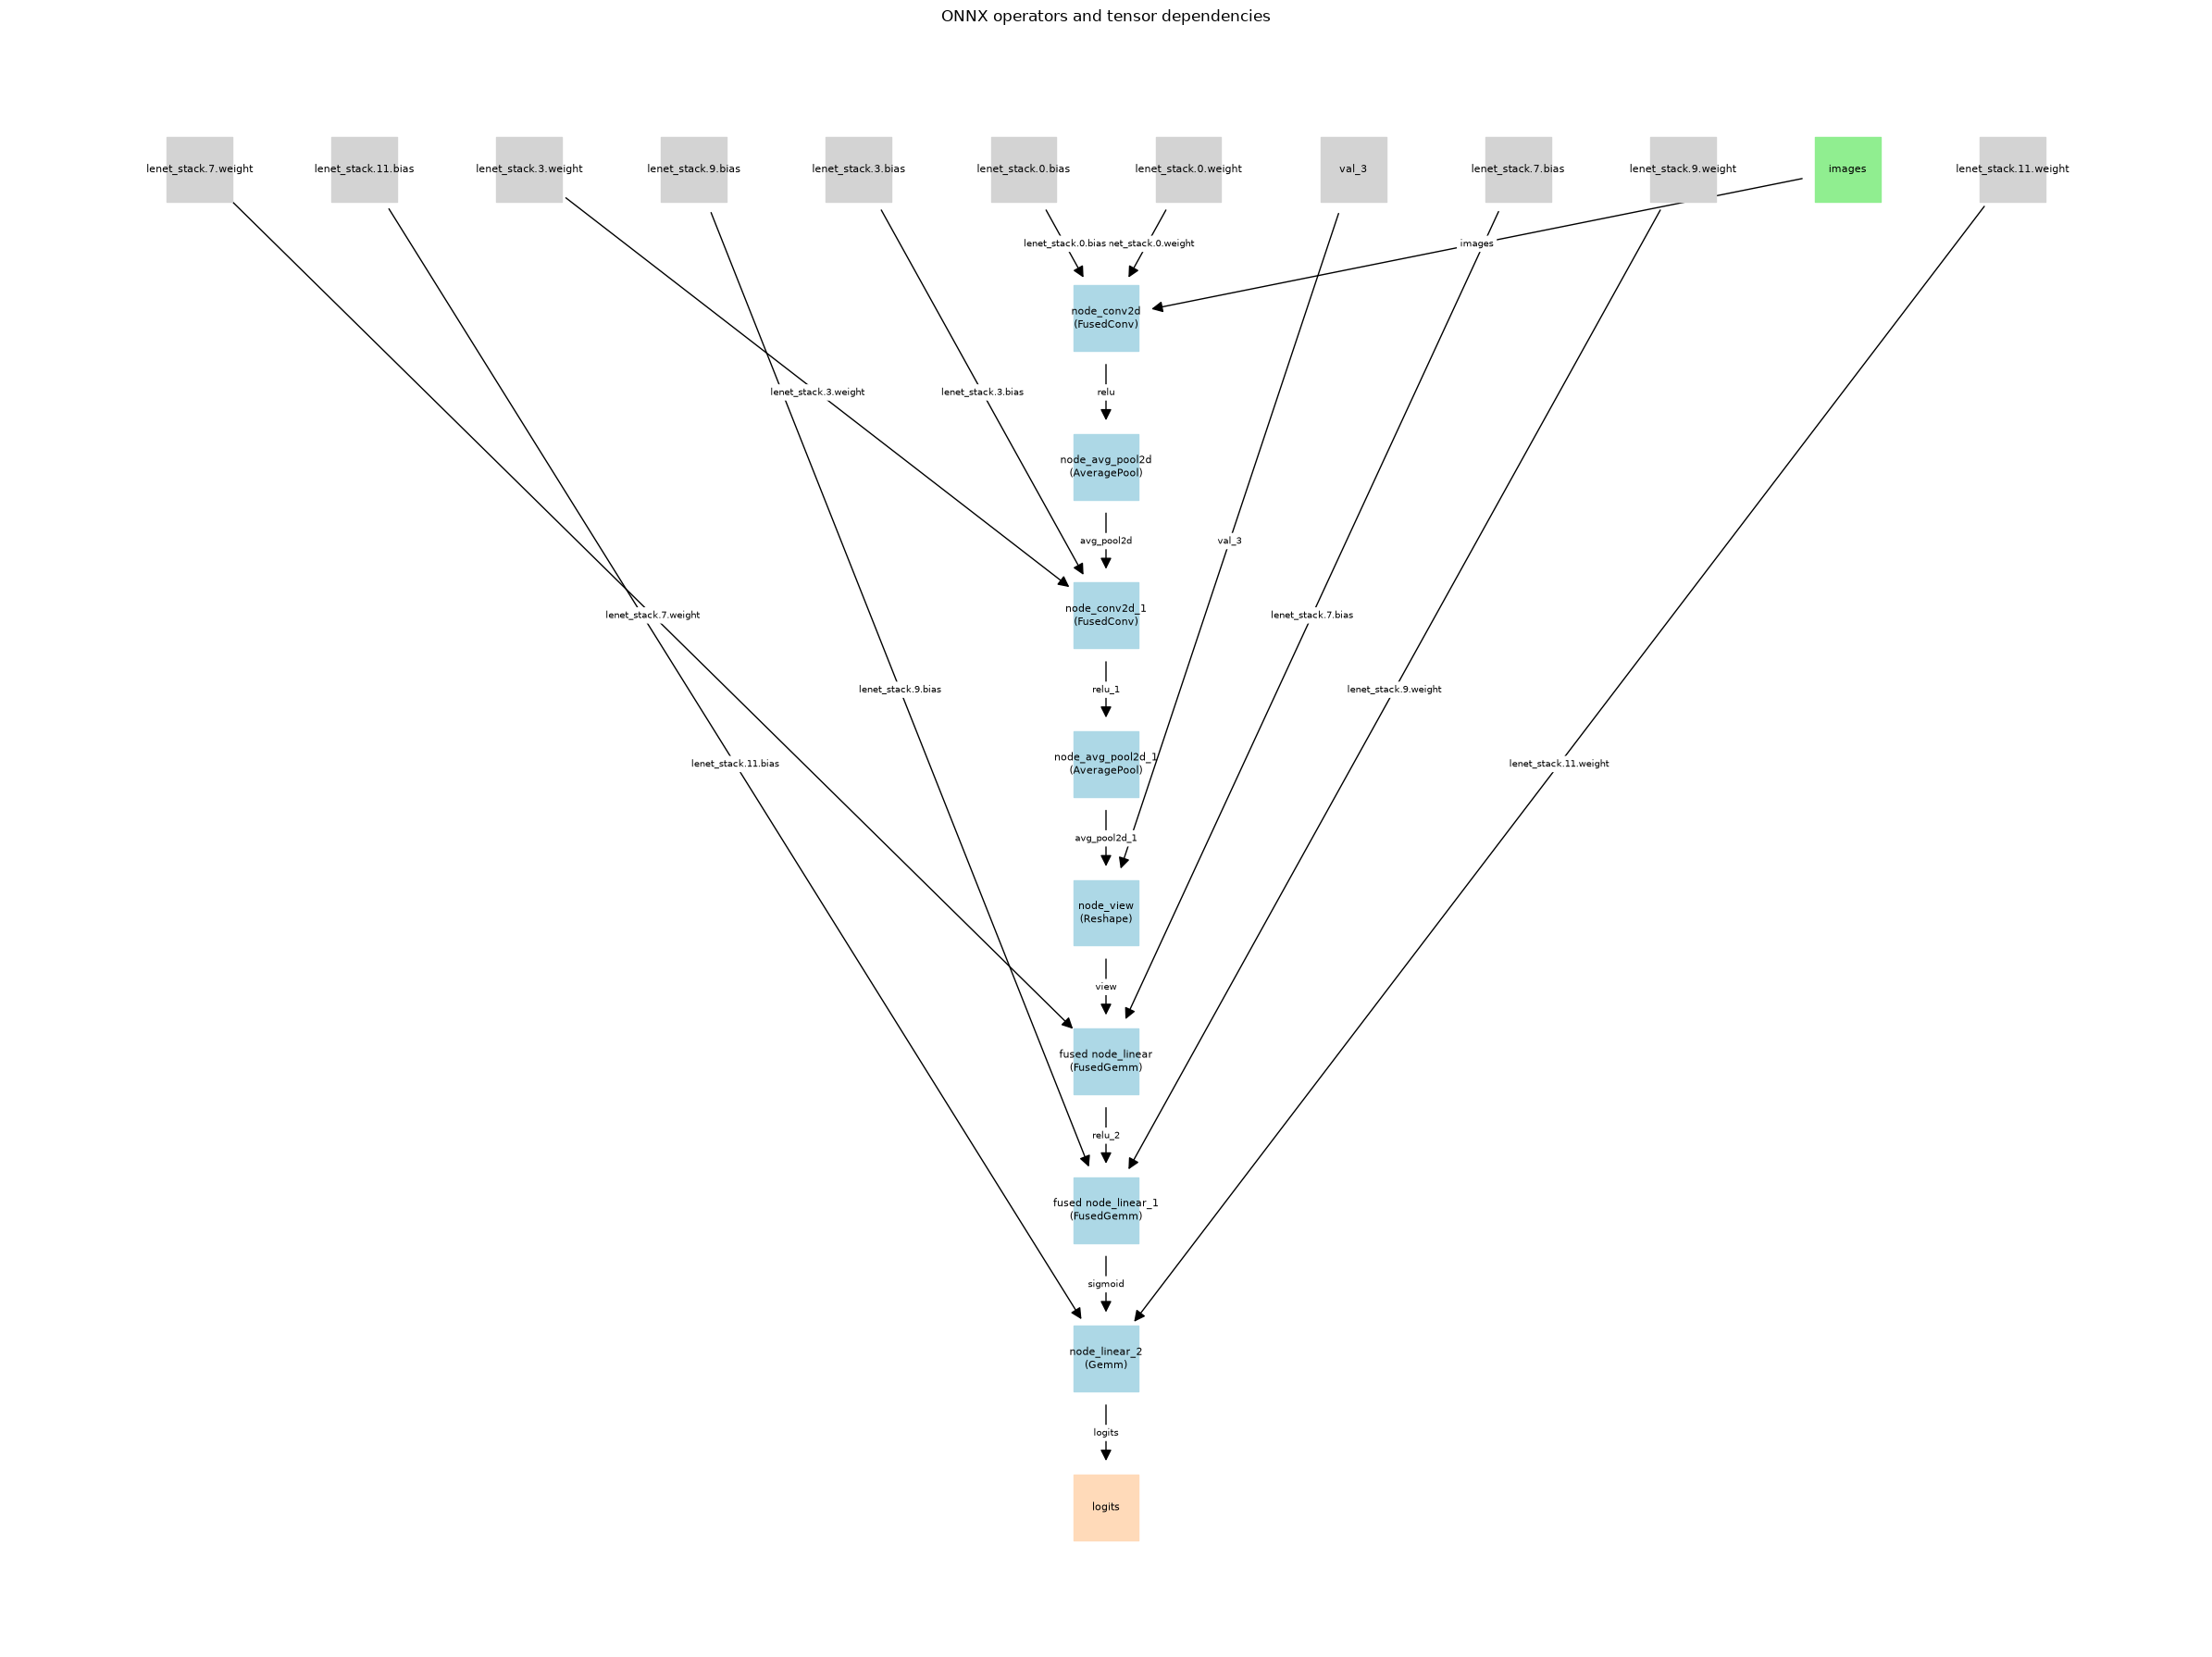

In [10]:
draw_model(optimized_model)

In [11]:
print(f'Node count: original = {len(model.graph.node)}, optimized = {len(optimized_model.graph.node)}')
print(f'Initializer count: original = {len(model.graph.initializer)}, optimized = {len(optimized_model.graph.initializer)}')


Node count: original = 12, optimized = 8
Initializer count: original = 11, optimized = 11


## Optimization explanation

Let's take a first level. In the optimized model operations **Conv**+ **Relu** has been replaced with a single operation **FusedConv**. 
Consequtive operations **Gemm**+**Relu** replaced with a single operation **FusedGemm**, it has a separate attribue *activation* function that can be equal to Relu, Sigmoid etc.

Fused operators combine convolution or matrix multiplication with activation in a single fused operation, potentially avoiding a separate pass over the intermediate tensor.



## Compare performace

In [53]:
import numpy as np

def measure_inference(optimization_type, profiling=True):
    sess_options = onnxruntime.SessionOptions()
    sess_options.graph_optimization_level = optimization_type
    sess_options.enable_profiling = profiling
    sess_options.enable_mem_reuse =  True
    onnxruntime_session = onnxruntime.InferenceSession(lenet.onnx_filename, sess_options)
    onnxruntime_session.run(None, {"images": X[0].reshape(1, *X[0].shape)})[0].reshape(-1)
    repeats = 1000
    inference_times = []
    start = time.perf_counter()
    for _ in range(repeats):
        for i in range(X.shape[0]):
            inference_start = time.perf_counter_ns()
            onnxruntime_session.run(None, {"images": X[i].reshape(1, *X[i].shape)})[0].reshape(-1)
            inference_end = time.perf_counter_ns()
            inference_times.append(inference_end - inference_start)

    end = time.perf_counter()

    preformance_report = onnxruntime_session.end_profiling()

    return end - start, np.array(inference_times), preformance_report



nonopimized_time, nonoptimized_times, nonoptimized_report = measure_inference(onnxruntime.GraphOptimizationLevel.ORT_DISABLE_ALL)
optimized_time, optimized_times, optimized_report = measure_inference(onnxruntime.GraphOptimizationLevel.ORT_ENABLE_EXTENDED)


In [13]:
import json
optimized_report_json = json.load(open(optimized_report))
nonoptimized_report_json = json.load(open(nonoptimized_report))

In [14]:
import pandas as pd

optimized_df = pd.json_normalize(optimized_report_json)
optimized_df["optimized"] = True

nonoptimized_df = pd.json_normalize(nonoptimized_report_json)
nonoptimized_df["optimized"] = False


In [15]:
optimized_df.head()

,cat,pid,tid,dur,ts,ph,name,args.mem_requested_in_use_delta,args.output_type_shape,args.mem_arena_held,...,args.thread_scheduling_stats.sub_threads.135133688489664.num_run,args.thread_scheduling_stats.sub_threads.135133688489664.core,args.thread_scheduling_stats.sub_threads.135133696882368.num_run,args.thread_scheduling_stats.sub_threads.135133696882368.core,args.mem_in_use_peak,args.node_index,args.provider,args.mem_bytes_in_use,args.mem_arena_held_delta,optimized
0,Session,2521689,2521689,850,15,X,model_loading_uri,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,Session,2521689,2521689,1917,902,X,session_initialization,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2,Node,2521689,2521689,133,2956,X,node_conv2d_kernel_time,43200,"[{'float': [1, 12, 30, 30]}]",1689960,...,0.0,-1.0,0.0,-1.0,815720,14,CPUExecutionProvider,684648,1048576,True
3,Node,2521689,2521689,78,3097,X,node_avg_pool2d_kernel_time,10800,"[{'float': [1, 12, 15, 15]}]",1689960,...,0.0,-1.0,0.0,-1.0,815720,2,CPUExecutionProvider,695656,0,True
4,Node,2521689,2521689,83,3183,X,node_conv2d_1_kernel_time,21632,"[{'float': [1, 32, 13, 13]}]",1689960,...,1.0,2.0,1.0,3.0,957800,15,CPUExecutionProvider,695656,0,True


In [16]:
nonoptimized_df.head()

,cat,pid,tid,dur,ts,ph,name,args.mem_in_use_delta,args.thread_scheduling_stats.main_thread.thread_pool_name,args.thread_scheduling_stats.main_thread.thread_id,...,args.mem_bytes_requested_in_use,args.mem_arena_held,args.mem_bytes_in_use,args.activation_size,args.node_index,args.parameter_size,args.mem_requested_in_use_delta,args.op_name,args.mem_in_use_peak,optimized
0,Session,2521689,2521689,903,300,X,model_loading_uri,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,Session,2521689,2521689,1184,1243,X,session_initialization,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,Node,2521689,2521689,142,2602,X,node_conv2d_kernel_time,43264,session-2-intra-op,135135618842752,...,684584,1689960,684648,3136,0,480,43200,Conv,815720,False
3,Node,2521689,2521689,22,2752,X,node_relu_kernel_time,0,session-2-intra-op,135135618842752,...,684584,1689960,684648,43200,1,0,0,Relu,815720,False
4,Node,2521689,2521689,80,2780,X,node_avg_pool2d_kernel_time,11008,session-2-intra-op,135135618842752,...,695384,1689960,695656,43200,2,0,10800,AveragePool,815720,False


In [32]:
report_df = pd.concat([optimized_df, nonoptimized_df])
report_df.head()

,cat,pid,tid,dur,ts,ph,name,args.mem_requested_in_use_delta,args.output_type_shape,args.mem_arena_held,...,args.thread_scheduling_stats.sub_threads.135133688489664.num_run,args.thread_scheduling_stats.sub_threads.135133688489664.core,args.thread_scheduling_stats.sub_threads.135133696882368.num_run,args.thread_scheduling_stats.sub_threads.135133696882368.core,args.mem_in_use_peak,args.node_index,args.provider,args.mem_bytes_in_use,args.mem_arena_held_delta,optimized
0,Session,2521689,2521689,850,15,X,model_loading_uri,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,Session,2521689,2521689,1917,902,X,session_initialization,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2,Node,2521689,2521689,133,2956,X,node_conv2d_kernel_time,43200,"[{'float': [1, 12, 30, 30]}]",1689960,...,0.0,-1.0,0.0,-1.0,815720,14,CPUExecutionProvider,684648,1048576,True
3,Node,2521689,2521689,78,3097,X,node_avg_pool2d_kernel_time,10800,"[{'float': [1, 12, 15, 15]}]",1689960,...,0.0,-1.0,0.0,-1.0,815720,2,CPUExecutionProvider,695656,0,True
4,Node,2521689,2521689,83,3183,X,node_conv2d_1_kernel_time,21632,"[{'float': [1, 32, 13, 13]}]",1689960,...,1.0,2.0,1.0,3.0,957800,15,CPUExecutionProvider,695656,0,True


In [33]:
report_df.columns

Index(['cat', 'pid', 'tid', 'dur', 'ts', 'ph', 'name',
       'args.mem_requested_in_use_delta', 'args.output_type_shape',
       'args.mem_arena_held', 'args.mem_bytes_requested_in_use',
       'args.activation_size', 'args.output_size', 'args.parameter_size',
       'args.mem_in_use_delta', 'args.input_type_shape', 'args.op_name',
       'args.thread_scheduling_stats.main_thread.thread_pool_name',
       'args.thread_scheduling_stats.main_thread.thread_id',
       'args.thread_scheduling_stats.main_thread.block_size',
       'args.thread_scheduling_stats.main_thread.core',
       'args.thread_scheduling_stats.main_thread.Distribution',
       'args.thread_scheduling_stats.main_thread.DistributionEnqueue',
       'args.thread_scheduling_stats.main_thread.Run',
       'args.thread_scheduling_stats.main_thread.Wait',
       'args.thread_scheduling_stats.main_thread.WaitRevoke',
       'args.thread_scheduling_stats.sub_threads.135133680096960.num_run',
       'args.thread_scheduling_stat

In [36]:
report_df.info()

<class 'pandas.DataFrame'>
Index: 1536028 entries, 0 to 896015
Data columns (total 38 columns):
 #   Column                                                            Non-Null Count    Dtype  
---  ------                                                            --------------    -----  
 0   cat                                                               1536028 non-null  str    
 1   pid                                                               1536028 non-null  int64  
 2   tid                                                               1536028 non-null  int64  
 3   dur                                                               1536028 non-null  int64  
 4   ts                                                                1536028 non-null  int64  
 5   ph                                                                1536028 non-null  str    
 6   name                                                              1536028 non-null  str    
 7   args.mem_requested_in_use_

In [35]:
numeric_columns = ["args.mem_bytes_in_use", "args.mem_in_use_peak"]
report_df[numeric_columns] = report_df[numeric_columns].apply(pd.to_numeric)

In [44]:
# report_df[["optimized", "name", "dur"] + numeric_columns].groupby(by="name").sum().sort_values(by="args.mem_bytes_in_use", ascending=False)

report_df.groupby(
    ["name", "optimized"], as_index=False
)[["dur"] + numeric_columns].sum().sort_values(
    by=["name", "optimized"],
    ascending=False,
)


,name,optimized,dur,args.mem_bytes_in_use,args.mem_in_use_peak
27,session_initialization,True,1917,0.000000e+00,0.000000e+00
26,session_initialization,False,1184,0.000000e+00,0.000000e+00
25,node_view_kernel_time,True,954548,4.452263e+10,6.130016e+10
24,node_view_kernel_time,False,1092425,4.452263e+10,6.130016e+10
23,node_sigmoid_kernel_time,False,1043544,4.452263e+10,6.130016e+10
22,node_relu_kernel_time,False,1461102,4.452267e+10,6.130002e+10
21,node_relu_2_kernel_time,False,1044862,4.452263e+10,6.130016e+10
20,node_relu_1_kernel_time,False,1261326,4.452267e+10,6.130016e+10
19,node_linear_kernel_time,False,2250265,4.452263e+10,6.130016e+10
18,node_linear_2_kernel_time,True,1042760,4.453901e+10,6.130016e+10


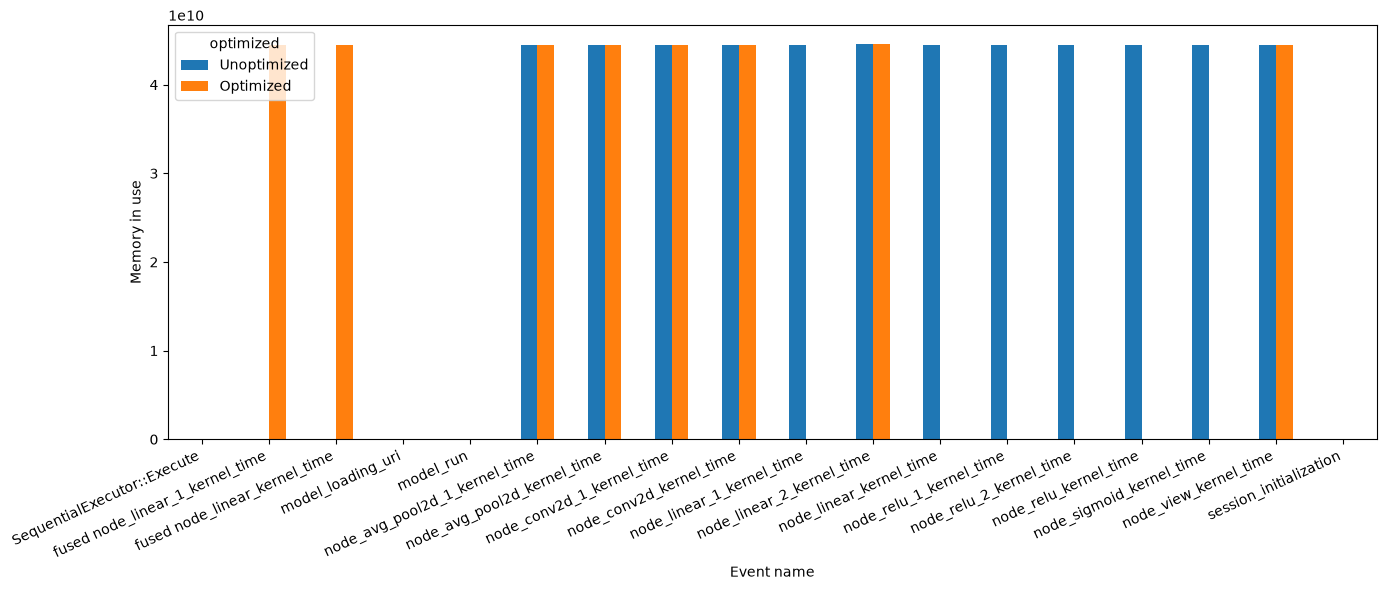

In [52]:
durations = (
    report_df.groupby(["name", "optimized"])["args.mem_bytes_in_use"]
    .sum()
    .unstack("optimized")
    .rename(columns={False: "Unoptimized", True: "Optimized"})
)

ax = durations.plot.bar(figsize=(14, 6))
ax.set_xlabel("Event name")
ax.set_ylabel("Memory in use")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
durations = (
    report_df.groupby(["name", "optimized"])["dur"]
    .sum()
    .unstack("optimized")
    .rename(columns={False: "Unoptimized", True: "Optimized"})
)

ax = durations.plot.bar(figsize=(14, 6))
ax.set_xlabel("Event name")
ax.set_ylabel("Mean duration (µs)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Inference Quantiles

In [22]:
print(np.quantile(nonoptimized_times, q=[0.5, 0.95]))
print(np.quantile(optimized_times, q=[0.5, 0.95]))


[520004.  762057.4]
[384267.5  560656.25]


## Intermediate shapes

In [23]:
original_model = onnx.load(lenet.onnx_filename)
infered_model = onnx.shape_inference.infer_shapes(original_model, strict_mode=True)

input_shape = infered_model.graph.input[0].type.tensor_type.shape
input_shape = [dim.dim_value for dim in input_shape.dim]
print(f'input_shape={input_shape}')
for value in infered_model.graph.value_info:
    tensor_type = value.type.tensor_type
    shape = [dim.dim_value if dim.HasField("dim_value") else dim.dim_param or "" 
             for dim in tensor_type.shape.dim]

    print(value.name, shape)

input_shape=[1, 1, 28, 28]
lenet_stack.0.weight [12, 1, 3, 3]
lenet_stack.0.bias [12]
lenet_stack.3.weight [32, 12, 3, 3]
lenet_stack.3.bias [32]
lenet_stack.7.weight [120, 1152]
lenet_stack.7.bias [120]
lenet_stack.9.weight [84, 120]
lenet_stack.9.bias [84]
lenet_stack.11.weight [10, 84]
lenet_stack.11.bias [10]
val_3 [2]
conv2d [1, 12, 30, 30]
relu [1, 12, 30, 30]
avg_pool2d [1, 12, 15, 15]
conv2d_1 [1, 32, 13, 13]
relu_1 [1, 32, 13, 13]
avg_pool2d_1 [1, 32, 6, 6]
view [1, 1152]
linear [1, 120]
relu_2 [1, 120]
linear_1 [1, 84]
sigmoid [1, 84]


# Compare optimization inference

In [24]:
def run_inference(optimization_type):
    sess_options = onnxruntime.SessionOptions()
    sess_options.graph_optimization_level = optimization_type
    sess_options.enable_mem_reuse =  True
    onnxruntime_session = onnxruntime.InferenceSession(lenet.onnx_filename, sess_options)
    inferences = []
    for i in range(X.shape[0]):
        inferences.append(onnxruntime_session.run(None, {"images": X[i].reshape(1, *X[i].shape)})[0].reshape(-1))

    return np.array(inferences)


logits_no_optimizations = run_inference(onnxruntime.GraphOptimizationLevel.ORT_DISABLE_ALL)
logits_optimizations = run_inference(onnxruntime.GraphOptimizationLevel.ORT_ENABLE_ALL)

max_logit_difference = np.max(np.abs(logits_optimizations - logits_no_optimizations))
print(f"Maximum logit difference {max_logit_difference}")

Maximum logit difference 2.86102294921875e-06
